# Handwritten Digit Recognition (MNIST)
**Goal:** classify 28x28 grayscale images of handwritten digits (0-9).

**Plan:** 1) Load & explore data  2) Baseline: SVM (classical ML)  3) Small CNN (deep learning)  4) Compare with accuracy / F1 / confusion matrix  5) Visualize predictions  6) Save the model.

## 1. Imports & settings

In [1]:
import os, gzip, struct, time, json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
os.makedirs("outputs", exist_ok=True)
print("TensorFlow", tf.__version__)

I0000 00:00:1791052769.130193     167 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791052771.825367     167 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 2. Load the MNIST dataset
We first try `keras.datasets.mnist` (needs internet). If that fails, we read the raw MNIST files from the `data/` folder (they came with the GitHub project).

In [2]:
def read_idx(path):
    with open(path, "rb") as f:
        magic, = struct.unpack(">I", f.read(4))
        ndim = magic & 0xFF
        shape = struct.unpack(">" + "I"*ndim, f.read(4*ndim))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(shape)

try:
    (X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
    print("Loaded from keras.datasets")
except Exception as e:
    print("Keras download failed -> using local files in data/")
    X_train = read_idx("data/train-images-idx3-ubyte"); y_train = read_idx("data/train-labels-idx1-ubyte")
    X_test  = read_idx("data/t10k-images-idx3-ubyte");  y_test  = read_idx("data/t10k-labels-idx1-ubyte")

print("Train:", X_train.shape, y_train.shape, "| Test:", X_test.shape, y_test.shape)

Keras download failed -> using local files in data/
Train: (60000, 28, 28) (60000,) | Test: (10000, 28, 28) (10000,)


## 3. Explore the data

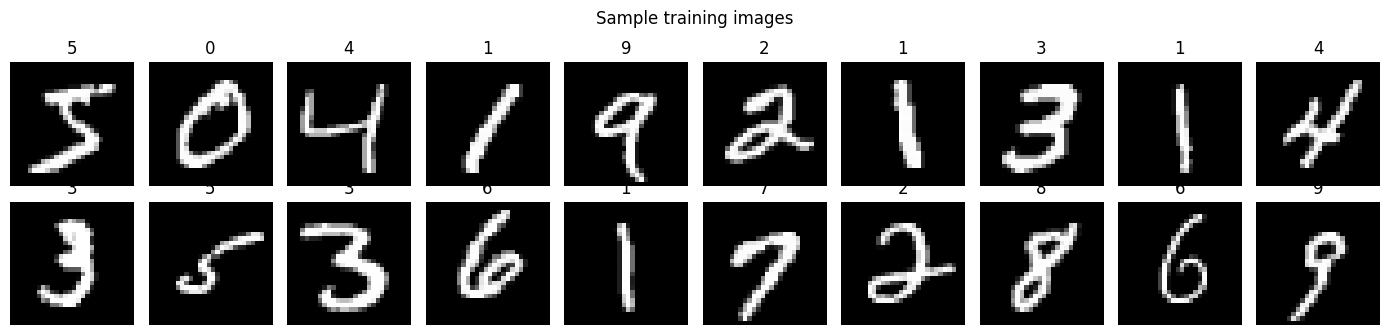

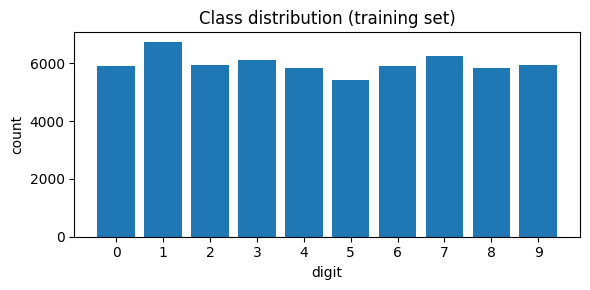

Pixel range: 0 - 255


In [3]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[i], cmap="gray"); ax.set_title(int(y_train[i])); ax.axis("off")
plt.suptitle("Sample training images"); plt.tight_layout()
plt.savefig("outputs/samples.png", dpi=120); plt.show()

counts = np.bincount(y_train)
plt.figure(figsize=(6,3)); plt.bar(range(10), counts); plt.xticks(range(10))
plt.title("Class distribution (training set)"); plt.xlabel("digit"); plt.ylabel("count")
plt.tight_layout(); plt.savefig("outputs/class_distribution.png", dpi=120); plt.show()
print("Pixel range:", X_train.min(), "-", X_train.max())

The classes are fairly balanced, and pixels range from 0 to 255, so we **normalize** them to 0-1.

## 4. Pre-processing

In [4]:
Xtr = X_train.astype("float32") / 255.0
Xte = X_test.astype("float32") / 255.0

# Flattened (784 features) for SVM; 28x28x1 images for CNN
Xtr_flat, Xte_flat = Xtr.reshape(len(Xtr), -1), Xte.reshape(len(Xte), -1)
Xtr_img,  Xte_img  = Xtr[..., None], Xte[..., None]
print(Xtr_flat.shape, Xtr_img.shape)

(60000, 784) (60000, 28, 28, 1)


## 5. Baseline model: SVM
SVMs on 60,000 images are slow, so for the baseline we train on the first **10,000** training images (and still test on the full 10,000 test images).

In [5]:
t0 = time.time()
svm = SVC(kernel="rbf", C=5, gamma="scale")
svm.fit(Xtr_flat[:10000], y_train[:10000])
svm_pred = svm.predict(Xte_flat)
svm_time = time.time() - t0

svm_acc = accuracy_score(y_test, svm_pred)
svm_f1  = f1_score(y_test, svm_pred, average="macro")
print(f"SVM  accuracy = {svm_acc:.4f} | macro F1 = {svm_f1:.4f} | time = {svm_time:.0f}s")

SVM  accuracy = 0.9679 | macro F1 = 0.9677 | time = 46s


## 6. Deep learning model: small CNN
Architecture: 2 x (Conv -> MaxPool) to learn visual features, then Dropout (reduces over-fitting) and a Dense softmax layer with 10 outputs.

In [6]:
cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.4),
    layers.Dense(10, activation="softmax"),
])
cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
t0 = time.time()
history = cnn.fit(Xtr_img, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=2)
cnn_time = time.time() - t0
print(f"Training time: {cnn_time:.0f}s")

Epoch 1/5


422/422 - 22s - 51ms/step - accuracy: 0.8976 - loss: 0.3445 - val_accuracy: 0.9787 - val_loss: 0.0755


Epoch 2/5


422/422 - 20s - 48ms/step - accuracy: 0.9687 - loss: 0.1017 - val_accuracy: 0.9853 - val_loss: 0.0529


Epoch 3/5


...

Epoch 4/5


422/422 - 20s - 46ms/step - accuracy: 0.9800 - loss: 0.0650 - val_accuracy: 0.9877 - val_loss: 0.0422


Epoch 5/5


422/422 - 22s - 52ms/step - accuracy: 0.9825 - loss: 0.0560 - val_accuracy: 0.9895 - val_loss: 0.0378


Training time: 125s


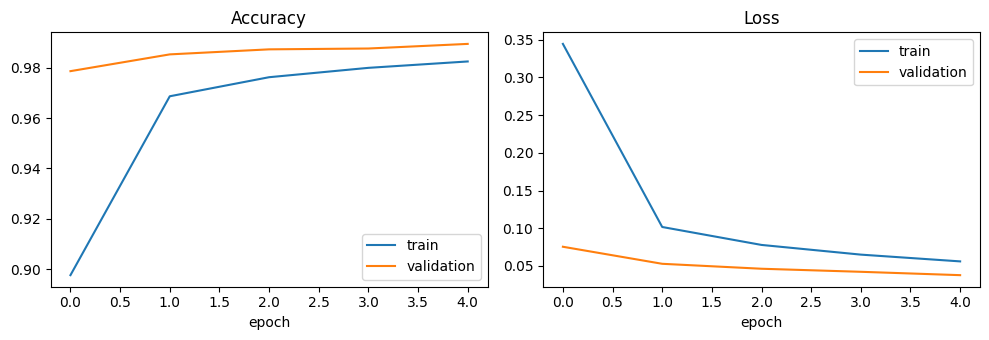

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history.history["accuracy"], label="train"); ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train"); ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("outputs/training_curves.png", dpi=120); plt.show()

## 7. Evaluation on the test set (10,000 unseen images)

In [9]:
cnn_prob = cnn.predict(Xte_img, verbose=0)
cnn_pred = cnn_prob.argmax(axis=1)
cnn_acc = accuracy_score(y_test, cnn_pred)
cnn_f1  = f1_score(y_test, cnn_pred, average="macro")

print(f"{'Model':<6}{'Accuracy':>10}{'Macro F1':>10}")
print(f"{'SVM':<6}{svm_acc:>10.4f}{svm_f1:>10.4f}")
print(f"{'CNN':<6}{cnn_acc:>10.4f}{cnn_f1:>10.4f}")
print("\nCNN per-class report:\n", classification_report(y_test, cnn_pred, digits=4))
json.dump({"svm_acc":svm_acc,"svm_f1":svm_f1,"svm_time":svm_time,"cnn_acc":cnn_acc,"cnn_f1":cnn_f1,"cnn_time":cnn_time},
          open("outputs/metrics.json","w"), indent=2)

Model   Accuracy  Macro F1
SVM       0.9679    0.9677
CNN       0.9883    0.9883

CNN per-class report:
               precision    recall  f1-score   support

           0     0.9858    0.9939    0.9898       980
           1     0.9869    0.9982    0.9926      1135
           2     0.9874    0.9855    0.9864      1032
           3     0.9940    0.9871    0.9906      1010
           4     0.9899    0.9980    0.9939       982
           5     0.9800    0.9910    0.9855       892
           6     0.9968    0.9833    0.9900       958
           7     0.9815    0.9815    0.9815      1028
           8     0.9897    0.9867    0.9882       974
           9     0.9910    0.9772    0.9840      1009

    accuracy                         0.9883     10000
   macro avg     0.9883    0.9882    0.9883     10000
weighted avg     0.9883    0.9883    0.9883     10000



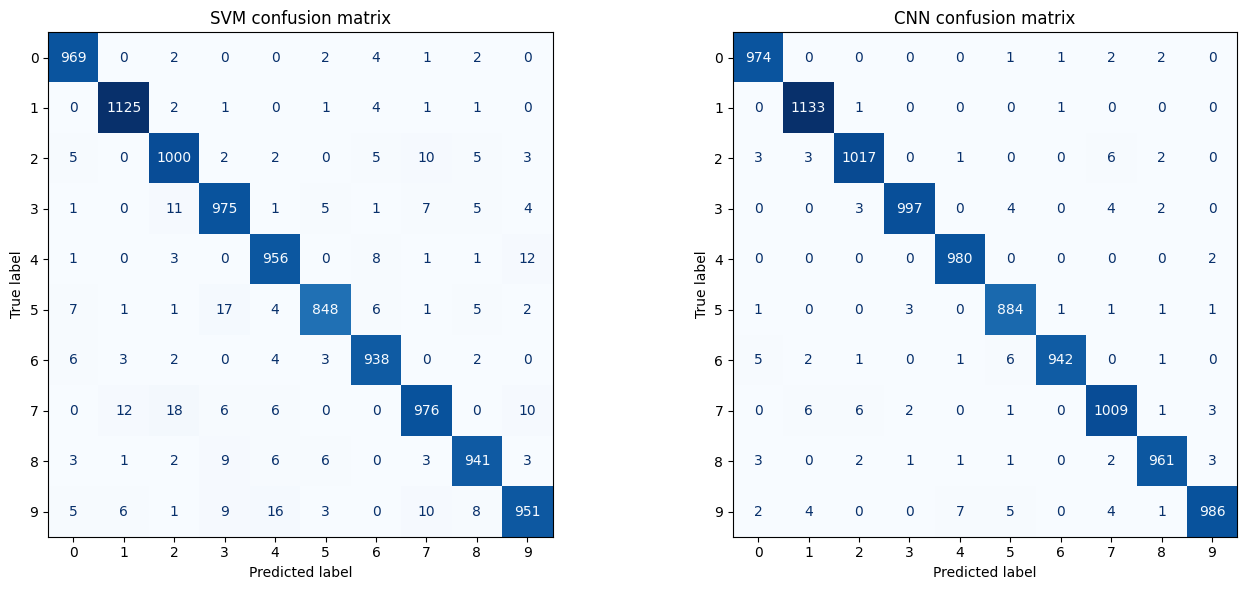

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, pred, name in [(ax[0], svm_pred, "SVM"), (ax[1], cnn_pred, "CNN")]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{name} confusion matrix")
plt.tight_layout(); plt.savefig("outputs/confusion_matrices.png", dpi=120); plt.show()

## 8. Visualize predictions

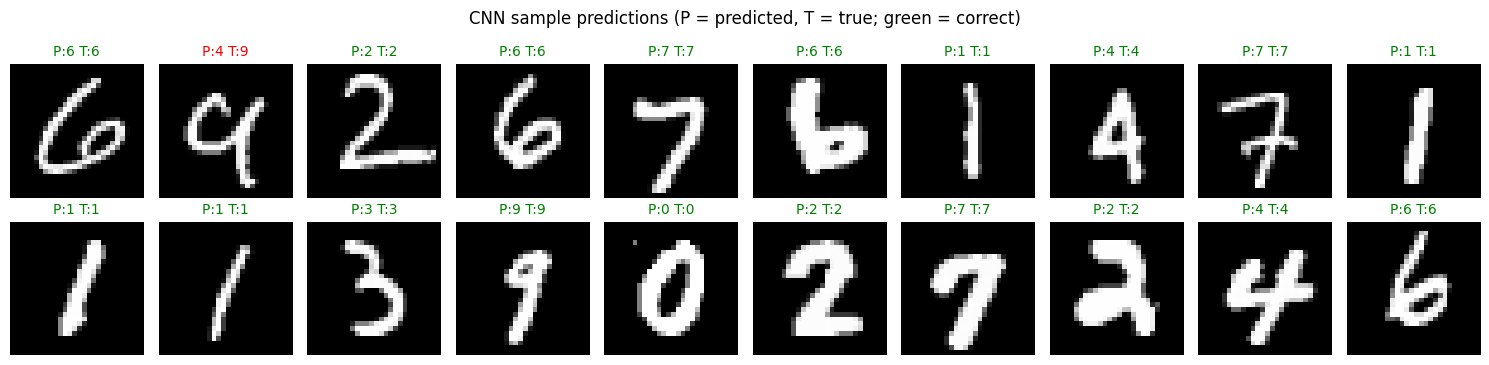

In [11]:
idx = np.random.RandomState(1).choice(len(Xte), 20, replace=False)
fig, axes = plt.subplots(2, 10, figsize=(15, 3.8))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_test[i], cmap="gray"); ok = cnn_pred[i] == y_test[i]
    ax.set_title(f"P:{cnn_pred[i]} T:{y_test[i]}", color="green" if ok else "red", fontsize=10); ax.axis("off")
plt.suptitle("CNN sample predictions (P = predicted, T = true; green = correct)")
plt.tight_layout(); plt.savefig("outputs/sample_predictions.png", dpi=120); plt.show()

CNN made 117 mistakes out of 10000


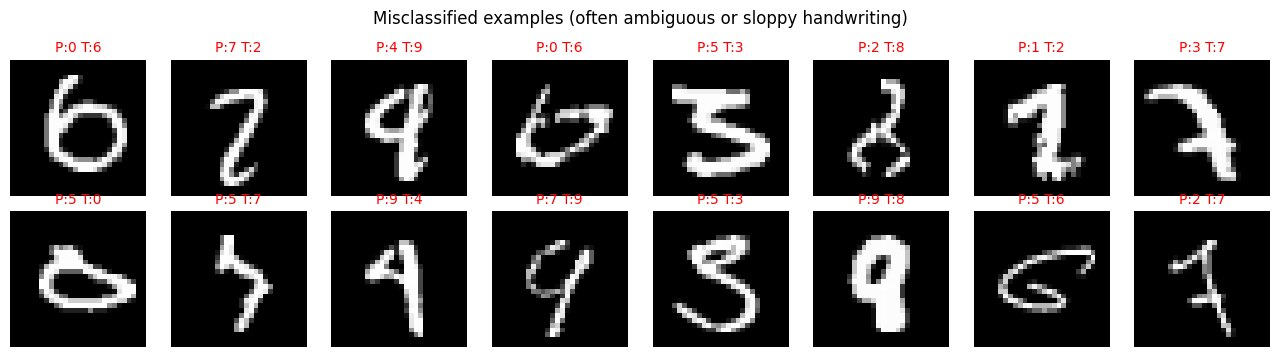

In [12]:
wrong = np.where(cnn_pred != y_test)[0]
print(f"CNN made {len(wrong)} mistakes out of {len(y_test)}")
fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for ax, i in zip(axes.ravel(), wrong[:16]):
    ax.imshow(X_test[i], cmap="gray"); ax.set_title(f"P:{cnn_pred[i]} T:{y_test[i]}", color="red", fontsize=10); ax.axis("off")
plt.suptitle("Misclassified examples (often ambiguous or sloppy handwriting)")
plt.tight_layout(); plt.savefig("outputs/misclassified.png", dpi=120); plt.show()

## 9. Save the model & reload it to prove it works

In [13]:
cnn.save("outputs/digit_cnn.keras")
import joblib; joblib.dump(svm, "outputs/digit_svm.joblib")

loaded = keras.models.load_model("outputs/digit_cnn.keras")
check = loaded.predict(Xte_img[:1000], verbose=0).argmax(axis=1)
print("Reloaded model accuracy on 1000 test images:", (check == y_test[:1000]).mean())

Reloaded model accuracy on 1000 test images: 0.986


## 10. Conclusion
- The **CNN clearly beats the SVM baseline**: it learns spatial features (strokes, loops) instead of treating pixels independently, and it trains on all 60,000 images.
- The SVM is a strong classical baseline but slow on the full dataset.
- Remaining errors are mostly visually ambiguous digits (e.g. 4/9, 3/5, 7/1).
- **Future work:** data augmentation (shifts, rotations), a deeper CNN, testing on real photos of digits.